# 经典与量子混合网络

输入两个数字，目标是学习 `y = 0.5 × x₀ − 0.3 × x₁`。
模型依次经过经典 Linear、参数化量子电路 PQC、经典 Linear。

PQC 创建时为每个旋转位置随机选择 RX、RY 或 RZ，之后门的种类保持固定，训练只更新角度。
这里严格执行两次参数更新，用来验证经典与量子部分已经接通，不要求两步就拟合完成。


In [1]:
from qutai import nn, qnn, visualization as vis


## 1. 准备两项输入和一个目标值

取 −1、0、1 组成九对数字。所有数据直接使用普通列表，不需要下载数据或新增依赖。


In [2]:
inputs = [[first, second] for first in (-1, 0, 1) for second in (-1, 0, 1)]
targets = [[0.5 * first - 0.3 * second] for first, second in inputs]

vis.Table(
    [[*sample, target[0]] for sample, target in zip(inputs, targets)],
    columns=["x₀", "x₁", "目标 y"],
    title="九个训练样本",
)


x₀,x₁,目标 y
-1,-1,-0.2
-1,0,-0.5
-1,1,-0.8
0,-1,0.3
0,0,0.0
0,1,-0.3
1,-1,0.8
1,0,0.5
1,1,0.2


## 2. 搭建经典 → 量子 → 经典模型

前面的 Linear 将两个输入变成两个角度；PQC 将角度编码到两个量子比特上，返回两个实数特征；最后的 Linear 将它们组合成一个预测值。

PQC 的深度为 2，所以共有四个可训练旋转角度。纠缠门默认是 CNOT，也可以写 `entangler="cz"`。
seed 只在这个示例中显式指定，方便对照结果；平时省略即可。电路结构不会在每次调用时重新随机。


固定的旋转门结构: (('RX', 'RY'), ('RZ', 'RX'))
量子权重形状: (2, 2)
全部可训练数值: 13


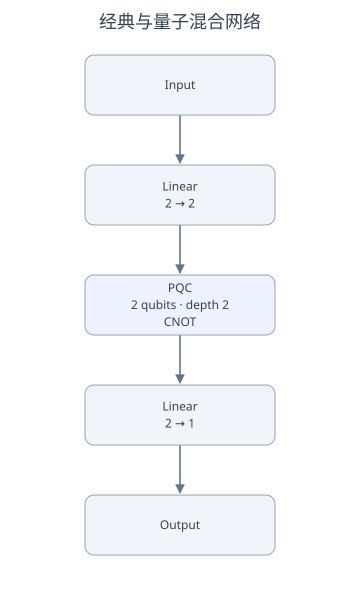

In [3]:
pqc = qnn.PQC(qubits=2, depth=2, seed=43)
model = nn.Model([
    nn.Linear(2, 2, seed=42),
    pqc,
    nn.Linear(2, 1, seed=44),
])

print("固定的旋转门结构:", pqc.rotations)
print("量子权重形状:", pqc.weight.shape)
print("全部可训练数值:", sum(parameter.size for parameter in model.parameters()))

vis.Network(model, title="经典与量子混合网络")


## 3. 看一个样本实际经过的量子电路

最左边的 RY 门负责输入编码。中间是两组随机旋转门与 CNOT，旋转角度来自 PQC 的可训练权重。

末尾的 RY(π/4) 是固定读出旋转，之后读取各比特的 Z 期望值。
这个固定旋转让读出同时包含原状态的 X、Z 信息，使 CZ 也能影响最终特征；它不增加可训练参数。

不同量子比特上互不冲突的门会紧凑排在同一列。画图只读取结构，不执行量子模拟。


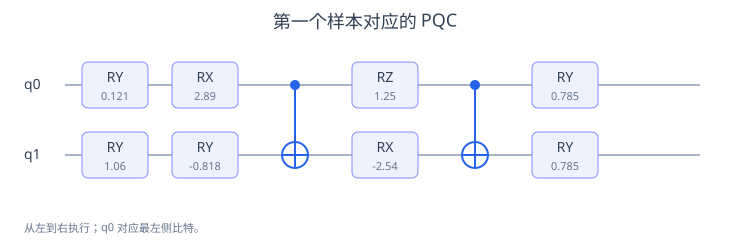

In [4]:
encoded = model.layers[0](inputs[0])
vis.Circuit(pqc.circuit(encoded), title="第一个样本对应的 PQC")


## 4. 损失函数和优化器保持原来的写法

SGD 会同时收集两侧 Linear 和中间 PQC 的参数。预测模式 `train=False` 暂停计算图记录，适合查看当前损失。


In [5]:
optimizer = nn.SGD(model, learning_rate=0.1)
loss_function = nn.MSE()
initial_loss = loss_function(model(inputs, train=False), targets).item()
history = [[0, initial_loss]]

print("训练前 MSE:", initial_loss)


训练前 MSE: 0.2185225489915716


## 5. 只更新两次参数

仍然是清除旧梯度、前向与损失、反向传播、更新参数四步。
量子电路默认用伴随求导计算输入角度和权重角度的梯度；输入角度的梯度继续传回前面的 Linear。参数移位仍可用于对照，两种方法共用同一套自动求导引擎。

每次更新后重新用预测模式计算 MSE，让三次记录可以直接比较。


In [6]:
for step in range(1, 3):
    optimizer.zero_grad()
    loss = loss_function(model(inputs), targets)
    loss.backward()
    optimizer.step()

    current_loss = loss_function(model(inputs, train=False), targets).item()
    history.append([step, current_loss])
    print(f"step {step}  MSE {current_loss:.8f}")

vis.Table(history, columns=["参数更新次数", "MSE"], title="两次更新的损失记录")


step 1  MSE 0.20909831
step 2  MSE 0.20253773


参数更新次数,MSE
0,0.2185225489915716
1,0.20909830674392949
2,0.20253773175496886


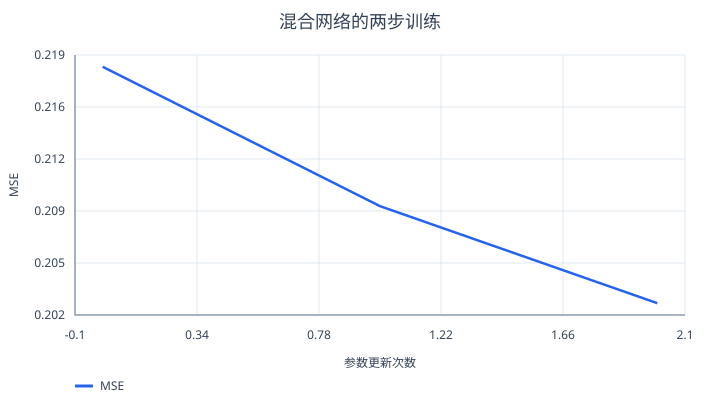

In [7]:
vis.Plot(title="混合网络的两步训练", xlabel="参数更新次数", ylabel="MSE").line(
    [row[0] for row in history], [row[1] for row in history], label="MSE"
)


## 6. 查看当前预测

两步训练只验证整个网络的计算、梯度与参数更新。可以在以后有更快后端时增加训练量。
本例结束于预测；保存加载已经由 SDK 测试覆盖，继续沿用 `nn.Model` 的接口。


In [8]:
prediction = model(inputs, train=False)
print("预测形状:", prediction.shape)
print("预测是否记录梯度:", prediction.requires_grad)

vis.Table(
    [[*sample, target[0], result[0]]
     for sample, target, result in zip(inputs, targets, prediction.tolist())],
    columns=["x₀", "x₁", "目标 y", "当前预测"],
    title="更新两次后的预测",
)


预测形状: (9, 1)
预测是否记录梯度: False


x₀,x₁,目标 y,当前预测
-1,-1,-0.2,-0.014411270102182842
-1,0,-0.5,0.001214612244246814
-1,1,-0.8,0.014921336251016784
0,-1,0.3,0.03515755129139315
0,0,0.0,0.06581501523395739
0,1,-0.3,0.08535171303318076
1,-1,0.8,0.09102228840635293
1,0,0.5,0.1218116117445783
1,1,0.2,0.1333771572828141
